               Age           HR        SysBP       MeanBP        DiaBP  \
count  2164.000000  2164.000000  2164.000000  2164.000000  2164.000000   
mean     65.322733    87.861922   121.142288    80.568787    56.042513   
std       8.798359    14.375420    13.349633     8.478831    12.467303   
min      42.057840    44.688946    49.183117    49.165665    12.090490   
25%      58.367389    78.603203   113.441900    75.130641    47.570493   
50%      64.877522    88.602921   121.508308    80.682595    56.005368   
75%      72.047543    97.848528   129.061293    85.937363    64.322665   
max      88.070390   148.043230   165.160640   112.066480   103.260000   

                RR            K           Na           Cl           Ca  ...  \
count  2164.000000  2164.000000  2164.000000  2164.000000  2164.000000  ...   
mean     22.418989     4.024324   141.848636   106.211118     7.809807  ...   
std       3.812953     0.520306     4.678850     3.972657     0.967647  ...   
min       9.73751

/tmp/ipykernel_2768019/648504199.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='GenderLabel', y='HR', palette='Set2')


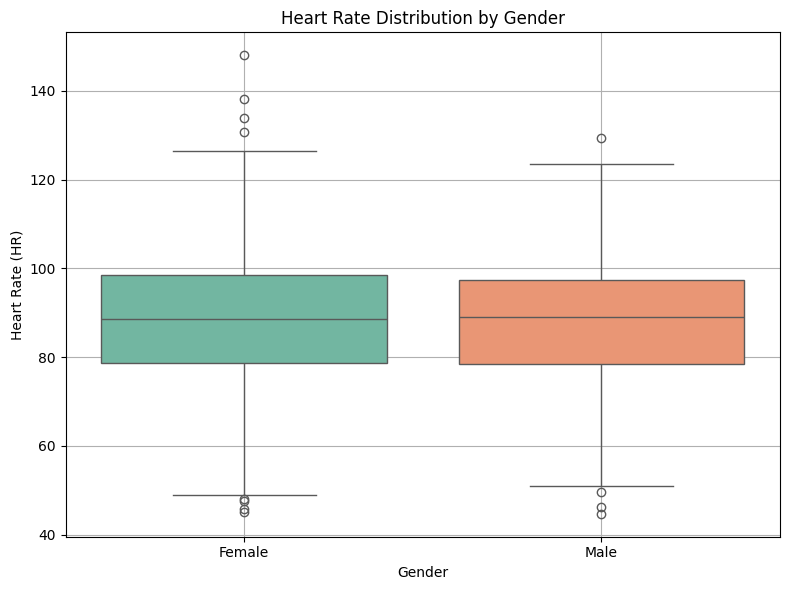

ValueError: Could not interpret value `AgeGroup` for `x`. An entry with this name does not appear in `data`.

<Figure size 1000x600 with 0 Axes>

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


df = pd.read_csv('sepsis.csv')
# print(df.describe())
# Ensure gender is labeled
df['GenderLabel'] = df['Gender'].map({0.0: 'Female', 1.0: 'Male'})

# 1. Boxplot of Heart Rate by Gender
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='GenderLabel', y='HR', palette='Set2')
plt.title('Heart Rate Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Heart Rate (HR)')
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. Violin plot of Systolic BP by Age Group
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x='AgeGroup', y='SysBP', palette='muted')
plt.title('Systolic Blood Pressure by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Systolic BP')
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Swarm plot for Diastolic BP by Gender
plt.figure(figsize=(8, 6))
sns.swarmplot(data=df, x='GenderLabel', y='DiaBP', palette='coolwarm', size=3)
plt.title('Diastolic BP by Gender')
plt.xlabel('Gender')
plt.ylabel('Diastolic BP')
plt.tight_layout()
plt.grid(True)
plt.show()

# 4. Pair Plot: Heart Rate, Systolic BP, Diastolic BP, Age
sns.pairplot(df[['HR', 'SysBP', 'DiaBP', 'Age', 'GenderLabel']], hue='GenderLabel', palette='coolwarm')
plt.suptitle('Pair Plot of Vital Signs by Gender', y=1.02)
plt.show()

# 5. Heatmap of correlations
plt.figure(figsize=(12, 10))
subset = df[['HR', 'SysBP', 'MeanBP', 'DiaBP', 'Age', 'SpO2', 'Temp']]
corr_matrix = subset.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', square=True, fmt=".2f")
plt.title('Correlation Heatmap of Selected Vital Signs')
plt.tight_layout()
plt.show()


In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare the fig folder
fig_dir = "fig"
os.makedirs(fig_dir, exist_ok=True)

# 2. Create AgeGroup and GenderLabel columns
age_bins = [0, 30, 45, 60, 75, 100]
age_labels = ['<30', '30–45', '45–60', '60–75', '75+']
df['AgeGroup'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels)
df['GenderLabel'] = df['Gender'].map({0.0: 'Female', 1.0: 'Male'})

# 3. Boxplot: Heart Rate by Gender
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='GenderLabel', y='HR', palette='Set2')
# plt.title('Heart Rate Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Heart Rate (HR)')
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "boxplot_heart_rate_by_gender.png"))
plt.close()

# 4. Violin Plot: Systolic BP by Age Group
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x='AgeGroup', y='SysBP', palette='muted')
# plt.title('Systolic Blood Pressure by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Systolic BP')
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "violinplot_sysbp_by_agegroup.png"))
plt.close()

# 5. Swarm Plot: Diastolic BP by Gender
plt.figure(figsize=(8, 6))
sns.swarmplot(data=df, x='GenderLabel', y='DiaBP', palette='coolwarm', size=3)
# plt.title('Diastolic BP by Gender')
plt.xlabel('Gender')
plt.ylabel('Diastolic BP')
plt.tight_layout()
plt.grid(True)
plt.savefig(os.path.join(fig_dir, "swarmplot_diabp_by_gender.png"))
plt.close()

# 6. Pairplot: Vital Signs by Gender (diag_kind='hist')
pairplot = sns.pairplot(
    data=df,
    vars=['HR', 'SysBP', 'DiaBP', 'Age'],
    hue='GenderLabel',
    palette='coolwarm',
    diag_kind='hist'
)
# pairplot.fig.suptitle('Pair Plot of Vital Signs by Gender', y=1.02)
pairplot.savefig(os.path.join(fig_dir, "pairplot_vital_signs_by_gender.png"))
plt.close()

# 7. Correlation Heatmap
plt.figure(figsize=(12, 10))
subset = df[['HR', 'SysBP', 'MeanBP', 'DiaBP', 'Age', 'SpO2', 'Temp']]
corr_matrix = subset.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', square=True, fmt=".2f")
# plt.title('Correlation Heatmap of Selected Vital Signs')
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "heatmap_correlation_vitals.png"))
plt.close()


/tmp/ipykernel_2768019/2205914835.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='GenderLabel', y='HR', palette='Set2')
/tmp/ipykernel_2768019/2205914835.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='AgeGroup', y='SysBP', palette='muted')
/tmp/ipykernel_2768019/2205914835.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(data=df, x='GenderLabel', y='DiaBP', palette='coolwarm', size=3)


In [7]:
import pandas as pd

# 1. Basic counts
num_samples = df.shape[0]
num_features = df.shape[1]

# 2. Attempt to infer the class column
possible_classes = [col for col in df.columns if df[col].nunique() <= 5 and df[col].nunique() > 1]
class_column = 'SepsisLabel' if 'SepsisLabel' in df.columns else (possible_classes[0] if possible_classes else None)

# 3. Class stats
if class_column:
    class_distribution = df[class_column].value_counts().to_dict()
    num_classes = len(class_distribution)
else:
    class_column = "Not specified"
    class_distribution = "N/A"
    num_classes = "N/A"

# 4. Create summary table
summary_df = pd.DataFrame({
    "Attribute": [
        "Number of Samples",
        "Number of Features",
        "Class Column",
        "Number of Classes",
        "Class Distribution"
    ],
    "Value": [
        num_samples,
        num_features,
        class_column,
        num_classes,
        str(class_distribution)
    ]
})

# 5. Display the summary
print(summary_df.to_string(index=False))


         Attribute                 Value
 Number of Samples                  2164
Number of Features                    46
      Class Column                Gender
 Number of Classes                     2
Class Distribution {0.0: 1576, 1.0: 588}
